# Volatility modelling

GARCH(1,1), GJR-GARCH(1,1), EGARCH(1,1). Gaussian quasi-likelihood with fixed training sample mean, constrained optimization and two starts. AIC/BIC are approximate conditional likelihood criteria; coefficient significance is not estimated. Variance forecasts use only preceding returns, with 80% chronological training. Squared returns are a noisy variance proxy; lower QLIKE is better. EGARCH log variance is bounded for numerical stability.

All returns are calculated from supplied adjusted close values; official exchange calendar and corporate actions are unverified. Observation steps may span missing trading dates.

In [1]:
from pathlib import Path
import sys
root=Path.cwd() if (Path.cwd()/"scripts").exists() else Path.cwd().parent
sys.path.insert(0,str(root/"scripts"))
from remaining_models import volatility
result=volatility()
display(result)

,Company,Model,Converged,Mean,Omega,Alpha,Gamma,Beta,AIC,BIC,Residual_LB_p,Squared_LB_p,ARCH_p,Test_QLIKE
0,JKH,GARCH,True,-0.004914,0.229888,0.197779,0.000000,0.708044,8027.176542,8050.269237,0.000007,0.999219,0.999208,1.554843
1,JKH,GJR-GARCH,True,-0.004914,0.234607,0.175669,0.052573,0.703183,8026.553654,8055.419523,0.000005,0.999305,0.999313,1.548632
2,JKH,EGARCH,True,-0.004914,0.097308,0.348686,-0.035143,0.901717,8041.464013,8070.329882,0.000002,0.995039,0.994780,1.539870
3,HAYL,GARCH,True,0.054896,0.167918,0.189357,0.000000,0.809643,9313.434375,9336.180861,0.012612,0.993747,0.993450,1.897599
4,HAYL,GJR-GARCH,True,0.054896,0.167255,0.180283,0.019072,0.809181,9314.854944,9343.288051,0.010979,0.992141,0.991857,1.898336
5,HAYL,EGARCH,True,0.054896,0.103521,0.306711,0.007158,0.957770,9285.983784,9314.416890,0.007942,0.954912,0.954928,1.908111
6,VONE,GARCH,True,0.052741,0.258161,0.155064,0.000000,0.821445,10748.655481,10771.664822,0.649154,0.181733,0.193099,2.098514
7,VONE,GJR-GARCH,True,0.052741,0.266468,0.144952,0.036531,0.815110,10748.380021,10777.141696,0.641954,0.176573,0.183321,2.091712
8,VONE,EGARCH,True,0.052741,0.098478,0.310569,-0.012935,0.960717,10757.283490,10786.045166,0.610471,0.058834,0.061023,2.131133


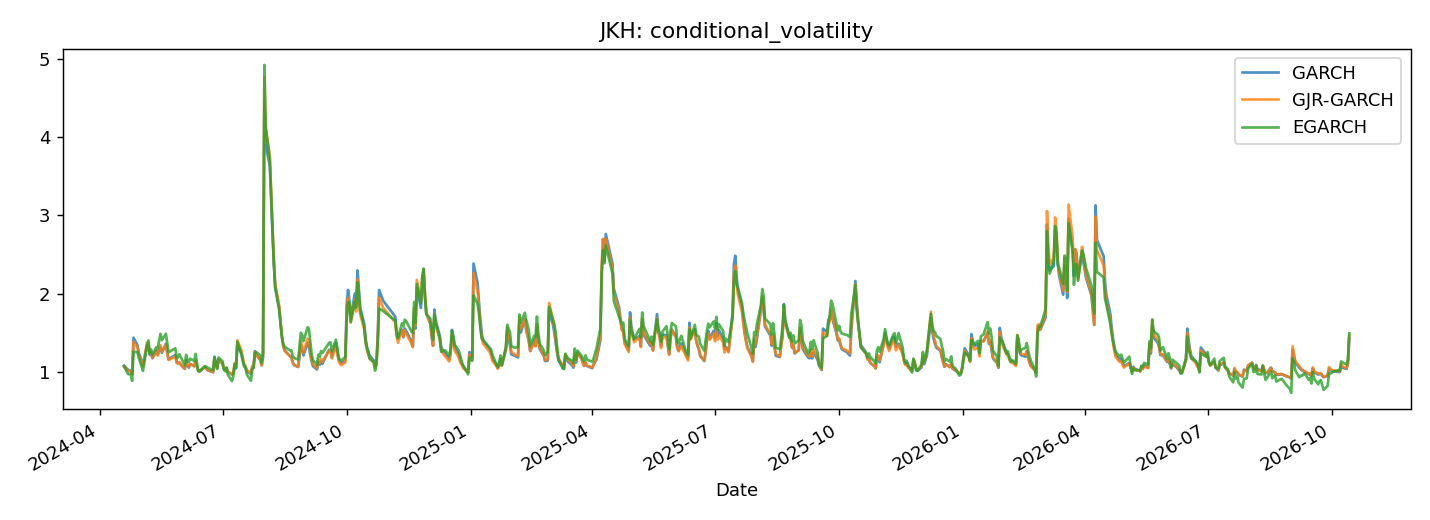

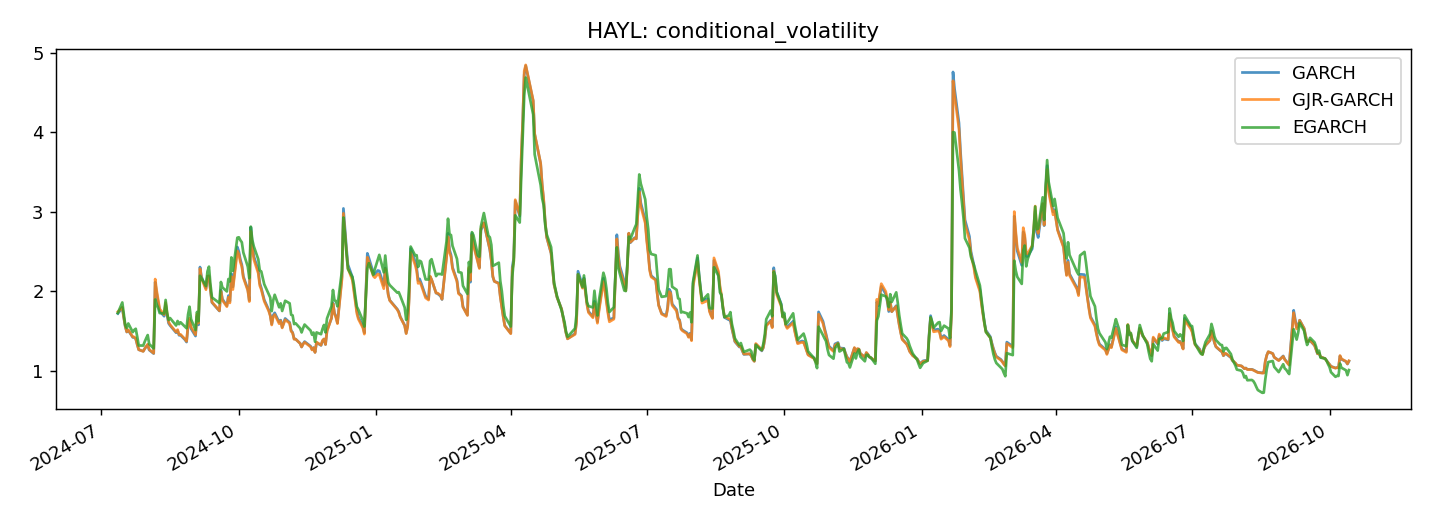

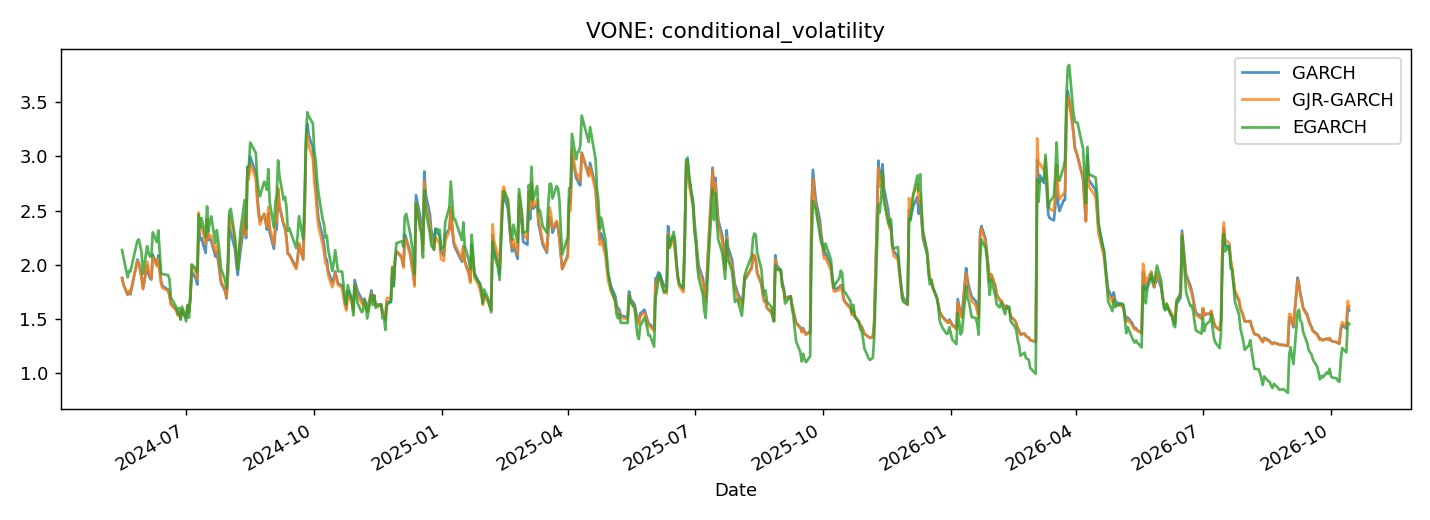

In [2]:
import pandas as pd
from IPython.display import display, Image
for asset in ["JKH","HAYL","VONE"]:
    display(Image(filename=str(root/"outputs/figures/conditional_volatility"/(asset+".png"))))

## Interpretation and limitations
All nine fits converged in the supplied run. Residual serial dependence remains for JKH and HAYL; a constant mean is a limitation. Training AIC and test QLIKE may select different models.